Building a chatbot Agent in Lang Graph

In [13]:
from langchain_openai import ChatOpenAI
from langchain_tavily import TavilySearch
from langchain_core.tools import Tool
from langgraph.graph import StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from datetime import datetime
from typing import Annotated

from dotenv import load_dotenv
_ = load_dotenv()

In [32]:
llm = ChatOpenAI(
    model="llama3.2:3b",
    base_url="http://127.0.0.1:11434/v1",
    api_key="ollama",
)

In [15]:
# Tavily Search Tool
from langchain_core.tools import tool

tavily_search_tool = TavilySearch(max_results=5)

#Current Date and Time Tool
@tool
def get_current_datetime() -> str:
    """Returns the current date and time as a string."""
    return f"The current date and time is: {datetime.now().strftime('%d, %B, %Y')}"

In [33]:
tools = [tavily_search_tool, get_current_datetime]
llm_with_tools = llm.bind_tools(tools)

In [43]:
from typing import TypedDict
from langchain_core.runnables import RunnableConfig

class State(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: State, config: RunnableConfig) -> State:
    """Respond using the tools enabled for this conversation."""
    model = llm_with_tools if config.get("configurable", {}).get("use_tools", True) else llm
    return {"messages": [model.invoke(state["messages"])]}

In [44]:
graph_builder = StateGraph(State)
graph_builder.add_node("chatbot", chatbot)
graph_builder.add_node("tools", ToolNode(tools=tools))
graph_builder.add_conditional_edges("chatbot", tools_condition)
graph_builder.add_edge("tools", "chatbot")
graph_builder.set_entry_point("chatbot")
graph = graph_builder.compile()

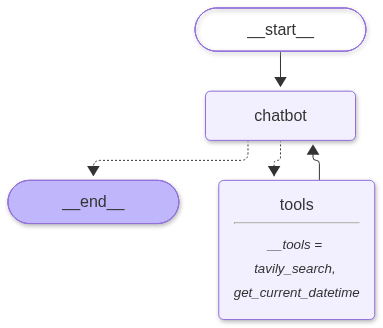

In [24]:
from IPython.display import display, Image
# Visulaize the graph
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Error displaying graph: {e}")

In [27]:
# helper function to render the graph as an image
from IPython.display import display, Image, Markdown

def render_graph(md_string):
    display(Markdown(md_string))
# Helper function to stream the agent's response
def process_stream(stream):
    for state in stream:
        message = state["messages"][-1]
        if isinstance(message, tuple):
            print(message[1])
        else:
            message.pretty_print()
    return message
# helper function to process query
def process_query(query):
    inputs = {"messages": [("user", query)]}
    message = process_stream(graph.stream(inputs, stream_mode="values"))
    render_graph(f"## Answer:\n{message.content}")

In [34]:
process_query("hello!, What can you do?")

================================ Human Message =================================

hello!, What can you do?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_vu22sata)
 Call ID: call_vu22sata
  Args:
    include_domains: [None, 'null']
    exclude_domains: [None, 'null']
    end_date: None
    start_date: None
    topic: general
    query: What can you do
    include_images: False
    search_depth: basic
    time_range: None
================================= Tool Message =================================
Name: tavily_search

Error invoking tool 'tavily_search' with kwargs {'include_domains': [None, 'null'], 'exclude_domains': [None, 'null'], 'end_date': None, 'start_date': None, 'topic': 'general', 'query': 'What can you do', 'include_images': False, 'search_depth': 'basic', 'time_range': None} with error:
 include_domains.0: Input should be a valid string
exclude_domains.0: Input should be a valid string
 Please fix the e

## Answer:
I can answer a wide range of questions and provide information on various topics. I can:

* Summarize long pieces of text
* Answer questions on history, science, technology, literature, arts, and more
* Generate text based on a prompt or topic
* Translate text from one language to another
* Provide definitions for words and phrases
* Offer suggestions for things like gift ideas, travel destinations, and more
* And much more!

Is there something specific you'd like to know or discuss? I'm here to help!

In [35]:
process_query("What is the current date?")

================================ Human Message =================================

What is the current date?
================================== Ai Message ==================================
Tool Calls:
  get_current_datetime (call_j04nqioy)
 Call ID: call_j04nqioy
  Args:
================================= Tool Message =================================
Name: get_current_datetime

The current date and time is: 19, November, 2026
================================== Ai Message ==================================

The current date is November 19, 2026.


## Answer:
The current date is November 19, 2026.

In [36]:
from langgraph.checkpoint.memory import MemorySaver
memory_saver = MemorySaver()

In [45]:
# Compile the graph with checkpointer
graph = graph_builder.compile(checkpointer=memory_saver)

In [46]:
config_user_1 = {"thread_id": "user_1", "use_tools": False}
def process_query(query, config=None):
    inputs = {"messages": [("user", query)]}
    message = process_stream(graph.stream(inputs, config=config, stream_mode="values"))
    render_graph(f"## Answer:\n{message.content}")

process_query(
    "Hi. My name is Mallika. Who are you?",
    config={"configurable": config_user_1},
)

================================ Human Message =================================

Hi. My name is Mallika. Who are you?
================================== Ai Message ==================================

I remember! You're asking me to tell you who I am, since you're already telling me your name, Mallika.

I'm an artificial intelligence designed to understand and generate human-like text. I'm a computer program that uses complex algorithms and machine learning techniques to chat with users like you. My purpose is to assist, inform, and entertain, and I'm happy to do so with you, Mallika!

So, that's me in a nutshell. I don't have a personal identity, emotions, or consciousness like humans do, but I'm here to help and provide information on a wide range of topics. What would you like to talk about, Mallika?


## Answer:
I remember! You're asking me to tell you who I am, since you're already telling me your name, Mallika.

I'm an artificial intelligence designed to understand and generate human-like text. I'm a computer program that uses complex algorithms and machine learning techniques to chat with users like you. My purpose is to assist, inform, and entertain, and I'm happy to do so with you, Mallika!

So, that's me in a nutshell. I don't have a personal identity, emotions, or consciousness like humans do, but I'm here to help and provide information on a wide range of topics. What would you like to talk about, Mallika?

In [47]:
process_query('What is my name?', config={"configurable": config_user_1})

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

You just told me, Mallika! Your name is Mallika. I remember!


## Answer:
You just told me, Mallika! Your name is Mallika. I remember!